# Analisis de hipotesis multivariada propuesta por nosotros:

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

listing_dataset = pd.read_csv("listings (1).csv.gz")
calendar_dataset = pd.read_csv("calendar.csv.gz")

listing_dataset['instant_bookable'].value_counts(dropna=False)

#copiamos el conjunto para preservarlo
preprocessed_dataset = listing_dataset.copy()

#borramos columnas con todos sus valores nulos
preprocessed_dataset = preprocessed_dataset.drop('neighborhood_overview', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_since', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_response_time', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_response_rate', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_acceptance_rate', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_thumbnail_url', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_neighbourhood', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_total_listings_count', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_verifications', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('neighbourhood', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('neighbourhood_group_cleansed', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('calendar_updated', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('instant_bookable', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('listing_url',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_url',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_profile_id',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_profile_url',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_name',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('scrape_id',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('picture_url',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_id',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('license',axis=1)

In [2]:
preprocessed_dataset['review_scores_location'].value_counts()

review_scores_location
5.00    7917
4.95    1102
4.94    1093
4.96    1047
4.93    1019
        ... 
3.78       1
3.94       1
3.71       1
1.50       1
2.83       1
Name: count, Length: 122, dtype: int64

**Hipotessis multivariada (nuestra):** A igual ocupancia anual estimada y a igual tipo de habitacion la ganancia depende del barrio donde se ubique el Airbnb.

Primero separamos las columnas que nos interesan que son `estimated_revenue_l365d`, `estimated_occupancy_l365d`, `room_type`, `neighbourhood_cleansed` y eliminamos las filas donde la ocupacion de los alojamientos sean cero ya que para este analisis no nos sirve las publicaciones sin ocupacion, tambien las filas nulas.

Otra modificacion que tendremos que hacer es la correccion de la distribucion para la estimacion de la ocupacion y la ganancia, aplicarle una correccion logarimica para mejorar la simetria de los atributos.

29685
estimated_revenue_l365d      1797
estimated_occupancy_l365d       0
room_type                       0
neighbourhood_cleansed          0
dtype: int64
Ocupación = 0: 7112
Filas finales: 21542


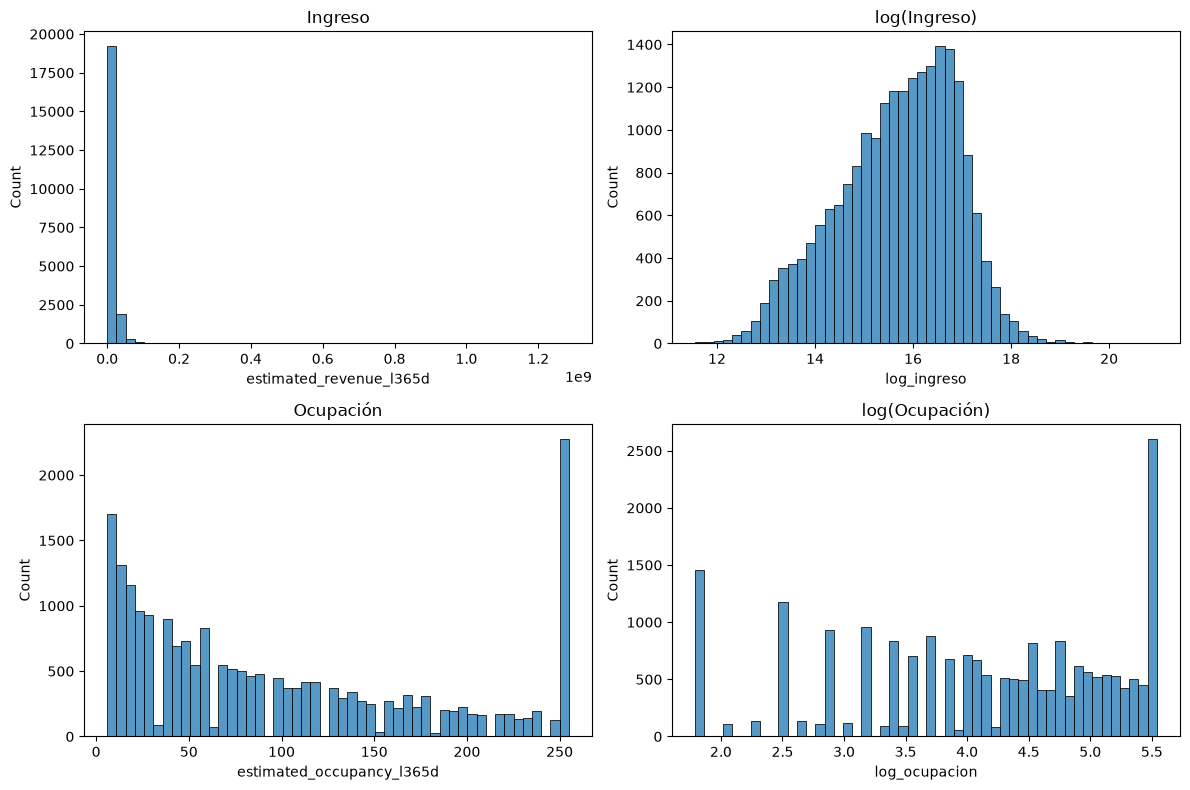

estimated_revenue_l365d      24.940566
log_ingreso                  -0.359095
estimated_occupancy_l365d     0.706049
log_ocupacion                -0.539934
dtype: float64


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Paso 1: selección y filtrado
cols = ['estimated_revenue_l365d', 'estimated_occupancy_l365d',
        'room_type', 'neighbourhood_cleansed']
df = preprocessed_dataset[cols].copy()

print(len(df))
print(df.isna().sum())
print('Ocupación = 0:', (df['estimated_occupancy_l365d'] == 0).sum())

df = df.dropna()
df = df[df['estimated_occupancy_l365d'] > 0]
print('Filas finales:', len(df))

# Paso 2: distribuciones, antes y después del log
df['log_ingreso'] = np.log(df['estimated_revenue_l365d'])
df['log_ocupacion'] = np.log(df['estimated_occupancy_l365d'])

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
sns.histplot(df['estimated_revenue_l365d'], bins=50, ax=axes[0, 0]).set_title('Ingreso')
sns.histplot(df['log_ingreso'], bins=50, ax=axes[0, 1]).set_title('log(Ingreso)')
sns.histplot(df['estimated_occupancy_l365d'], bins=50, ax=axes[1, 0]).set_title('Ocupación')
sns.histplot(df['log_ocupacion'], bins=50, ax=axes[1, 1]).set_title('log(Ocupación)')
plt.tight_layout()
plt.show()

print(df[['estimated_revenue_l365d', 'log_ingreso',
          'estimated_occupancy_l365d', 'log_ocupacion']].skew())

Como vemos en el histograma, hay un pico muy alto en la ocupacion de los alojamientos de 255 noches, aunque parezcan valores outliers, dentro del dominio y el contexto de lo que queremos verificar no lo son y son numeros razonables.

miramos los valores extremos de ingreso 

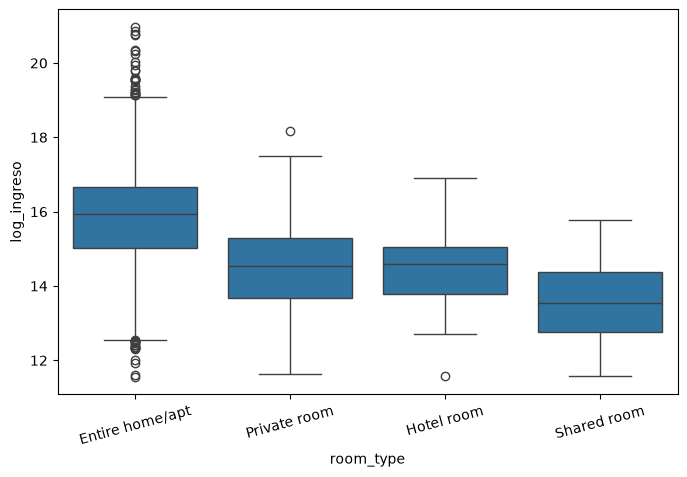

Bajos: 40 | Altos: 20
0.001    12.062069
0.005    12.608246
0.010    12.827522
0.990    18.048454
0.995    18.335794
0.999    19.192268
Name: log_ingreso, dtype: float64
       estimated_revenue_l365d  estimated_occupancy_l365d  precio_implicito  \
16054             4.987423e+08                        162      3.078656e+06   
18096             6.120601e+08                        180      3.400334e+06   
9612              6.657210e+08                         78      8.534884e+06   
8051              6.940518e+08                        102      6.804430e+06   
22904             1.029863e+09                          6      1.716438e+08   
990               1.064750e+09                         12      8.872920e+07   
15708             1.137534e+09                         66      1.723536e+07   
5593              1.285326e+09                        126      1.020100e+07   

             room_type neighbourhood_cleansed  
16054  Entire home/apt                Palermo  
18096  Entire home/apt

In [4]:
# Boxplot de log(ingreso) por tipo de habitación
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='room_type', y='log_ingreso')
plt.xticks(rotation=15)
plt.show()

# Outliers por regla del IQR (global)
q1, q3 = df['log_ingreso'].quantile([0.25, 0.75])
iqr = q3 - q1
bajos = df['log_ingreso'] < q1 - 1.5 * iqr
altos = df['log_ingreso'] > q3 + 1.5 * iqr
print('Bajos:', bajos.sum(), '| Altos:', altos.sum())

# Percentiles extremos
print(df['log_ingreso'].quantile([0.001, 0.005, 0.01, 0.99, 0.995, 0.999]))

# Precio implícito por noche, para ver de dónde vienen los extremos
df['precio_implicito'] = df['estimated_revenue_l365d'] / df['estimated_occupancy_l365d']
print(df.sort_values('log_ingreso').tail(8)[['estimated_revenue_l365d', 'estimated_occupancy_l365d',
                                              'precio_implicito', 'room_type', 'neighbourhood_cleansed']])

De momento con log ya controlamos casi todos los outlies pero todavia tenemos algunos, como vemos la regla del 1QR nos marca 60 filas (40 bajos y 20 altos), un 0,3% de las filas totales.

Tenemos claramente valores extremos que no tienen sentido por ejemplo en la fila 22904 nos encontramos con un alojamiento que es una casa entera ubicada en Villa Crespo, que cuenta con un total de 6 noches ocupadas en el año y marca una ingreso de 1029 millones de pesos, seguramente sea un error de tipeo por lo desproporcionado del valor.

Si bien podemos encontrar precios razonables dentro de los valores extremos, podemos suponer que sean alojamientos de para gente de "elite" y por lo general ese tipo lugares se suelen concentrar en barrios mas prestigiosos (Palermo, Recoleta, Puerto Madero), por ende tendriamos que hacer un recortes mas por errores de tipeo de forma momentanea.

In [5]:
df['precio_implicito'] = df['estimated_revenue_l365d'] / df['estimated_occupancy_l365d']

umbral = df['precio_implicito'].quantile(0.9995)
print('Umbral:', round(umbral))

df = df[df['precio_implicito'] <= umbral].copy()
print('Filas finales:', len(df))   # deberían quedar unas 21.531

Umbral: 5676245
Filas finales: 21531


Para los barrios que cuenten con pocos alojamientos los juntamos en una misma categoria ya que por separado no tienen el suficiente peso de validez por la cantidad de datos con los que cuentan, entonces los metemos en `Otros`

In [6]:
# Barrios con menos de 30 alojamientos pasan a "Otros"
vc = df['neighbourhood_cleansed'].value_counts()
chicos = vc[vc < 30].index
df['barrio'] = df['neighbourhood_cleansed'].where(~df['neighbourhood_cleansed'].isin(chicos), 'Otros')

print(df['barrio'].nunique(), 'categorías de barrio')
print(df['barrio'].value_counts())

31 categorías de barrio
barrio
Palermo             7360
Recoleta            2991
San Nicolas         1750
Monserrat           1054
Belgrano            1047
Retiro              1006
Balvanera            801
Villa Crespo         744
Almagro              740
San Telmo            610
Colegiales           423
Chacarita            369
Nuñez                357
Caballito            305
Puerto Madero        295
Constitucion         261
Villa Urquiza        219
Otros                203
Barracas             152
Saavedra             118
San Cristobal        106
Flores               101
Villa Del Parque      80
Boca                  76
Villa Devoto          64
Boedo                 63
Villa Ortuzar         60
Coghlan               60
Parque Patricios      43
Parque Chacabuco      39
Parque Chas           34
Name: count, dtype: int64


Ahora que hemos acomodado el dataset tiraremos un par de boxplot sobre relaciones bivariadas.

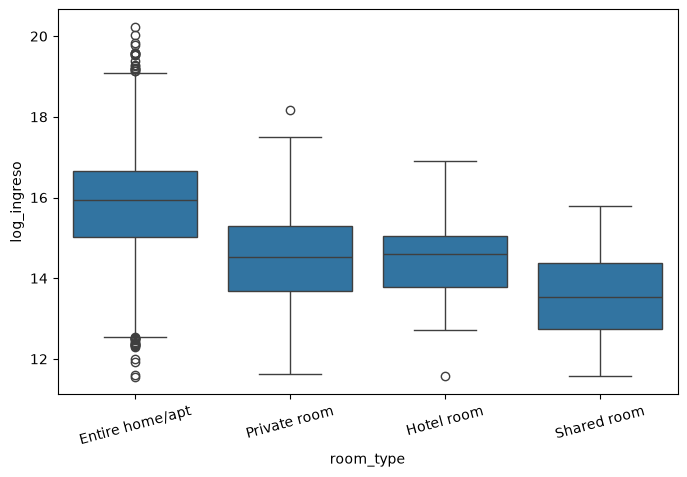

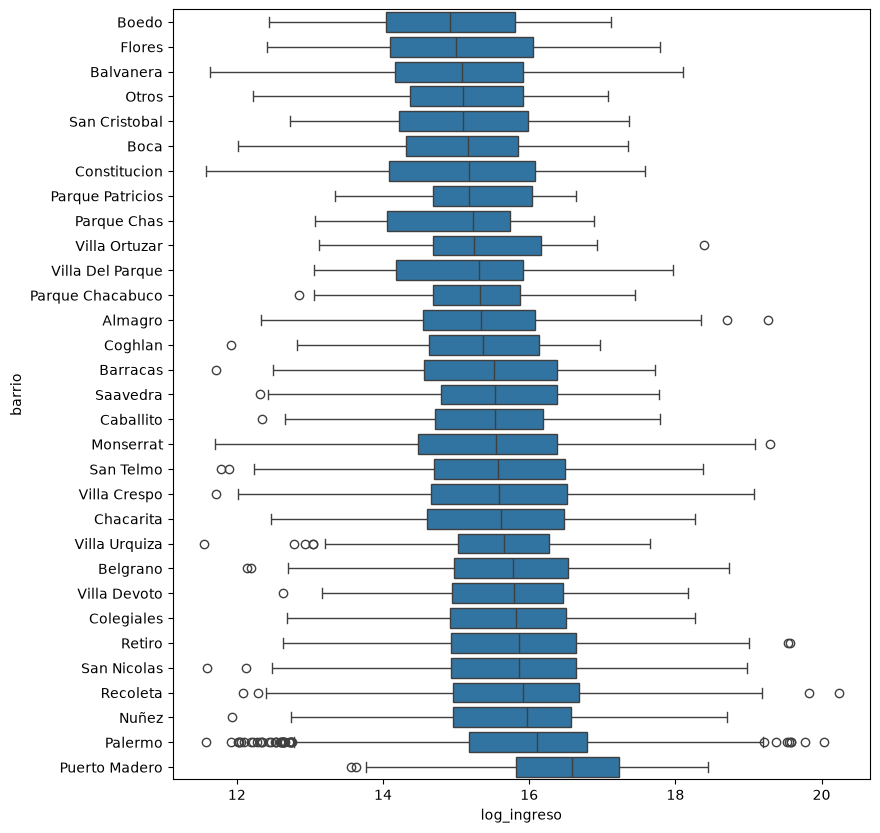

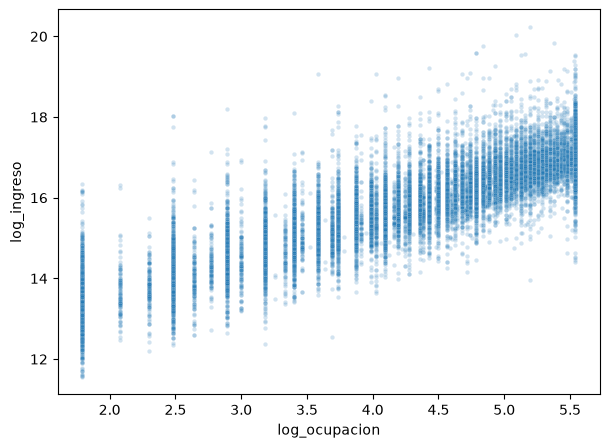

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. log(ingreso) por tipo de habitación
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='room_type', y='log_ingreso')
plt.xticks(rotation=15)
plt.show()

# 2. log(ingreso) por barrio, ordenado por mediana
orden = df.groupby('barrio')['log_ingreso'].median().sort_values().index
plt.figure(figsize=(9, 10))
sns.boxplot(data=df, y='barrio', x='log_ingreso', order=orden)
plt.show()

# 3. log(ingreso) contra log(ocupación)
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x='log_ocupacion', y='log_ingreso', alpha=0.2, s=10)
plt.show()

Si vemos nos enfocamos solamente en el grafico de boxplots de barrios con ingresos, ya podemos notar que el barrio si tiene cierta influencia en el ingreso final de un host, a su vez vemos un moviemiento logico de ingreso con ocupacion de un crecimiento de la "nube" que sube linealmente en proporcion de la cantidad de ocupacion que un alojamiento tiene.

Por parte del boxplot de `type_room` podemos ver un movimiento de las cajas con sentido por un tema de el tamaño y lo que contempla cada categoria, donde las casas enteras suelen ser mas caras y las habitacion compartidas son las mas baratas.

Ahora controlaremos el comportamiento con la tabla cruzada de barrio x tipo de habitacion con las 31 categorias.

In [8]:
tabla = pd.crosstab(df['barrio'], df['room_type'])
tabla['Total'] = tabla.sum(axis=1)
tabla = tabla.sort_values('Total', ascending=False)
tabla.loc['Total'] = tabla.sum()

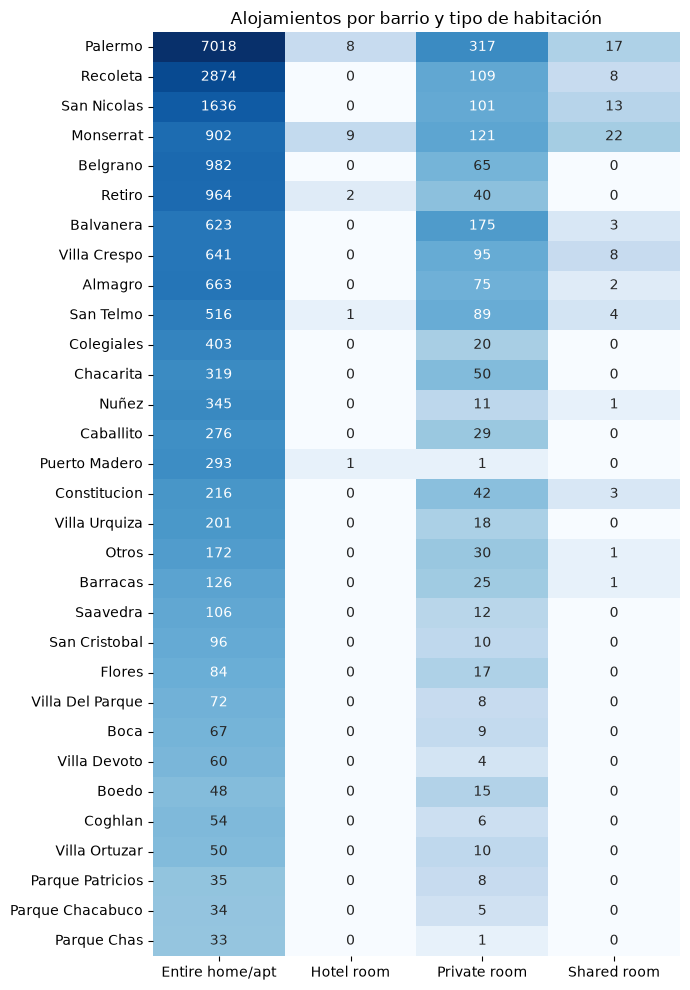

In [9]:
datos = tabla.drop(index='Total', columns='Total')

plt.figure(figsize=(7, 10))
sns.heatmap(np.log1p(datos), annot=datos, fmt='d', cmap='Blues', cbar=False)
plt.title('Alojamientos por barrio y tipo de habitación')
plt.xlabel('')
plt.ylabel('')
plt.tight_layout()
plt.savefig('tabla_cruzada.png', dpi=200)
plt.show()

Viendo la tabla cruzada, vemos como fuera de Palermo y Monserrat practicamente no existen ni habitaciones de hotel y hay muy pocas habitaciones compartidas tambien distribuidas en pocos barrios haciendo que no podamos comparar entre barrios estas categorias. Sin embargo, para el proposito de los barrios sigue siendonos util mantenerlos en el analisis.

**Planteo de hipótesis**

Modelo:

$$\log(\text{ingreso}_i) = \beta_0 + \beta_1 \log(\text{ocupación}_i) + \text{(efectos del tipo de habitación)} + \sum_{j=1}^{30} \gamma_j \, \text{barrio}_{ij} + \varepsilon_i$$

donde cada $\gamma_j$ es la diferencia en el logaritmo del ingreso anual esperado del barrio $j$ respecto de Palermo (categoría de referencia), a igual ocupación y tipo de habitación.

- $H_0: \gamma_1 = \gamma_2 = \dots = \gamma_{30} = 0$. A igual ocupación y tipo de habitación, el barrio no afecta el ingreso anual esperado.
- $H_1$: existe al menos un $j$ tal que $\gamma_j \neq 0$. El barrio afecta el ingreso anual esperado.

Se trata de una hipótesis conjunta sobre los 30 coeficientes de barrio, por lo que se contrasta con un test F de Wald. Nivel de significación: $\alpha = 0{,}05$.

In [10]:
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

# Modelo completo: ocupación + tipo + barrio (referencia: Palermo)
modelo = smf.ols(
    "log_ingreso ~ log_ocupacion + C(room_type) + C(barrio, Treatment(reference='Palermo'))",
    data=df
).fit()
print(modelo.summary())

# Modelo base, sin barrio, para el test F de modelos anidados
modelo_base = smf.ols("log_ingreso ~ log_ocupacion + C(room_type)", data=df).fit()
print(anova_lm(modelo_base, modelo))

                            OLS Regression Results                            
Dep. Variable:            log_ingreso   R-squared:                       0.832
Model:                            OLS   Adj. R-squared:                  0.832
Method:                 Least Squares   F-statistic:                     3140.
Date:                Sat, 07 Nov 2026   Prob (F-statistic):               0.00
Time:                        20:17:40   Log-Likelihood:                -15504.
No. Observations:               21531   AIC:                         3.108e+04
Df Residuals:                   21496   BIC:                         3.136e+04
Df Model:                          34                                         
Covariance Type:            nonrobust                                         
                                                                    coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------

In [11]:
import pandas as pd
import numpy as np

ci = modelo.conf_int()
tabla_coef = pd.DataFrame({
    'coef': modelo.params,
    'p_valor': modelo.pvalues,
    'ic_inf': ci[0],
    'ic_sup': ci[1],
    'dif_%': (np.exp(modelo.params) - 1) * 100
}).round(3)

# Limpiar los nombres largos
tabla_coef.index = (tabla_coef.index
                    .str.replace(r"C\(barrio, Treatment\(reference='Palermo'\)\)\[T\.", "barrio: ", regex=True)
                    .str.replace(r"C\(room_type\)\[T\.", "tipo: ", regex=True)
                    .str.replace("]", "", regex=False))

pd.set_option('display.max_rows', None)
tabla_coef

,coef,p_valor,ic_inf,ic_sup,dif_%
Intercept,11.980,0.000,11.951,12.008,1.594644e+07
tipo: Hotel room,-0.473,0.000,-0.687,-0.260,-3.770300e+01
tipo: Private room,-0.689,0.000,-0.716,-0.663,-4.980900e+01
tipo: Shared room,-1.457,0.000,-1.565,-1.350,-7.671800e+01
barrio: Almagro,-0.307,0.000,-0.345,-0.270,-2.645500e+01
barrio: Balvanera,-0.323,0.000,-0.360,-0.287,-2.762700e+01
barrio: Barracas,-0.159,0.000,-0.239,-0.079,-1.467800e+01
barrio: Belgrano,-0.046,0.006,-0.078,-0.013,-4.451000e+00
barrio: Boca,-0.239,0.000,-0.351,-0.126,-2.124700e+01
barrio: Boedo,-0.450,0.000,-0.573,-0.326,-3.621700e+01


Vemos como la ocupacion tiene un coeficiente casi igual a 1 (0.937), y como los coeficientes de los barrios cocuerdan con lo visto en el boxplot anteriormente, teniendo a Puerto Madero con una diferencia del 71% mas en el precio comparandolo con Palermo y Parque Chas tiene un precio 38% menor. Todavia no podemos confirmar que esto sea asi por que son supuetos, nos hace falta tratar con los residuos y ver si hay linealidad y si existe la homocedasticidad

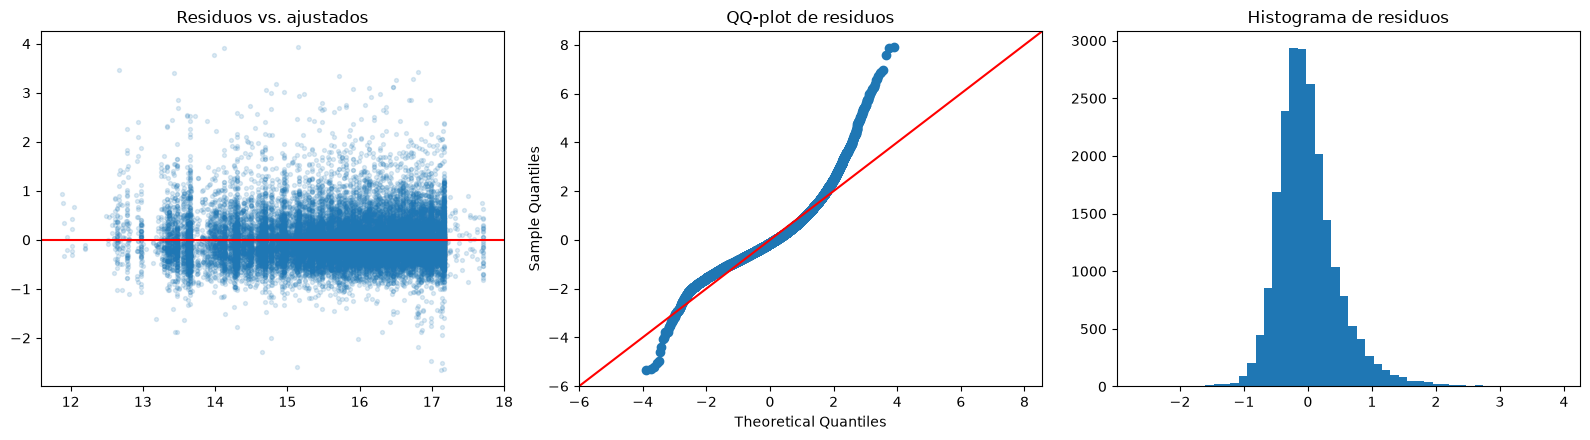

Breusch-Pagan p-valor: 3.273940009095673e-09


In [12]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan

res = modelo.resid
ajustados = modelo.fittedvalues

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Residuos vs. ajustados (linealidad y homocedasticidad)
axes[0].scatter(ajustados, res, alpha=0.15, s=8)
axes[0].axhline(0, color='red')
axes[0].set_title('Residuos vs. ajustados')

# Normalidad
sm.qqplot(res, line='45', fit=True, ax=axes[1])
axes[1].set_title('QQ-plot de residuos')

# Histograma de residuos
axes[2].hist(res, bins=50)
axes[2].set_title('Histograma de residuos')

plt.tight_layout()
plt.show()

# Breusch-Pagan (homocedasticidad)
bp = het_breuschpagan(res, modelo.model.exog)
print('Breusch-Pagan p-valor:', bp[1])

In [17]:
from scipy.stats import shapiro

muestra_res = modelo.resid.sample(5000, random_state=42)
W, p = shapiro(muestra_res)
print('Shapiro-Wilk (muestra de 5.000 residuos): W =', round(W, 4), '| p =', p)

Shapiro-Wilk (muestra de 5.000 residuos): W = 0.9201 | p = 1.6740098150470182e-45


Vemos como hay una heterocedasticidad en los residuos y como en el qq-plot hay una cola hacia arriba en la parte derecha que sube hasta 8 devios posiblemente debido a ese 0.05% que eliminamos, luego el test de Breusch-Pagan nos confirma lo que hay en el grafico, no existe la homocedasticidad en el conjunto.

La falta de normalidad casi no afecta a la inferencia sobre los coeficientes, no siendo un problema serio para la hipotesis. Vemos tambien como shapiro-Wilks rechaza la normalidad de los residuos al dar un valor menor a 0.001, usando 5000 muestras por limitacion por que el test de Shapiro no funciona muy bien para muestras tan grandes como este caso.

In [13]:
modelo_robusto = modelo.get_robustcov_results(cov_type='HC3')

In [15]:
import numpy as np
import pandas as pd

modelo_r = modelo.get_robustcov_results(cov_type='HC3')

comp = pd.DataFrame({
    'coef': modelo.params,
    'ee_normal': modelo.bse,
    'ee_robusto': pd.Series(modelo_r.bse, index=modelo.params.index),
    'p_normal': modelo.pvalues,
    'p_robusto': pd.Series(modelo_r.pvalues, index=modelo.params.index),
}).round(3)

pd.set_option('display.max_rows', None)
comp

,coef,ee_normal,ee_robusto,p_normal,p_robusto
Intercept,11.980,0.015,0.015,0.000,0.000
C(room_type)[T.Hotel room],-0.473,0.109,0.166,0.000,0.004
C(room_type)[T.Private room],-0.689,0.014,0.014,0.000,0.000
C(room_type)[T.Shared room],-1.457,0.055,0.036,0.000,0.000
"C(barrio, Treatment(reference='Palermo'))[T.Almagro]",-0.307,0.019,0.018,0.000,0.000
"C(barrio, Treatment(reference='Palermo'))[T.Balvanera]",-0.323,0.019,0.019,0.000,0.000
"C(barrio, Treatment(reference='Palermo'))[T.Barracas]",-0.159,0.041,0.039,0.000,0.000
"C(barrio, Treatment(reference='Palermo'))[T.Belgrano]",-0.046,0.016,0.016,0.006,0.004
"C(barrio, Treatment(reference='Palermo'))[T.Boca]",-0.239,0.057,0.060,0.000,0.000
"C(barrio, Treatment(reference='Palermo'))[T.Boedo]",-0.450,0.063,0.057,0.000,0.000


Como el test de Breusch-Pagan rechazo la homocedasticidad la inferencia se realiza con errores estandar robustos que son validos aun con heterocedasticidad.

In [20]:
wald = modelo_r.wald_test(R, use_f=True, scalar=True)
print(f"F({int(wald.df_num)}; {int(wald.df_denom)}) = {wald.statistic:.2f}")
print(f"p-valor = {wald.pvalue:.3e}")
print("Decisión (α = 0,05):", "se rechaza H0" if wald.pvalue < 0.05 else "no se rechaza H0")

F(30; 21496) = 60.44
p-valor = 0.000e+00
Decisión (α = 0,05): se rechaza H0


**Resultado del test**

El test F de Wald con errores estándar robustos (HC3), aplicado conjuntamente a los 30 coeficientes de barrio, da $F(30;\ 21.496) = 60{,}44$ con $p < 0{,}001$.

**Decisión**

Con un nivel de significación $\alpha = 0{,}05$, como $p < \alpha$, **se rechaza $H_0$**: $\gamma_1 = \gamma_2 = \dots = \gamma_{30} = 0$.

**Conclusión**

Existe evidencia estadísticamente significativa de que, a igual ocupación y tipo de habitación, el ingreso anual esperado depende del barrio. El resultado se mantiene aun corrigiendo por heterocedasticidad.

El rechazo de $H_0$ indica que los barrios, en conjunto, aportan información al modelo, pero no indica cuáles difieren entre sí: eso se analiza con los coeficientes individuales (28 de los 30 barrios difieren significativamente de Palermo; Colegiales y Villa Devoto no).